# 장기 추세 모델 — 최신 확인 결과

원래 Process 컬럼을 받고 선택한 1·4·8·12·24시간 내부를 5분 단위로 집계한다. 미래 예측이 아니라 해당 구간의 회고적 이상 판정이다. 별도 검토한 정상 참고 28일과 수집 확인이 필요하다. 아래는 모델 고정 후 생성한 반합성 확인용 576개 사례의 집계 결과다. 실제 운영 장애 검증이나 공식 ADBench 성능이 아니다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'latest_inventory.json').exists())
read = lambda p: json.loads((ROOT/p).read_text(encoding='utf-8'))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
colors = ['#2563eb','#d97706','#059669']

r=read('reports/long_term_anomaly/five_minute_localized/confirmation_results.json')['results']
hours=[1,4,8,12,24]
metrics=['accuracy','precision','recall','f1']
rows=[{'hours':h,**r[str(h)]['median'],'max_scenario_fpr':r[str(h)]['maximum_scenario_fpr']} for h in hours]
table=pd.DataFrame(rows).set_index('hours')
display((table*100).round(3))

,accuracy,precision,recall,f1,max_scenario_fpr
hours,,,,,
1,92.903,80.474,76.395,76.957,4.100
4,94.892,96.726,69.966,80.782,0.658
8,95.522,98.013,73.116,83.429,0.445
12,95.562,97.976,73.408,83.638,0.362
24,95.227,98.318,71.234,82.237,0.319


## 1. 구간 길이에 따른 성능

네 지표는 **시나리오별 지표의 중앙값**이다. 모든 개별 시나리오의 최솟값이나 전체 시간 합산 수치가 아니다. FPR 열은 가장 높은 시나리오의 값이다. 4시간 Recall 중앙값은 69.97%로 70%보다 조금 낮다.

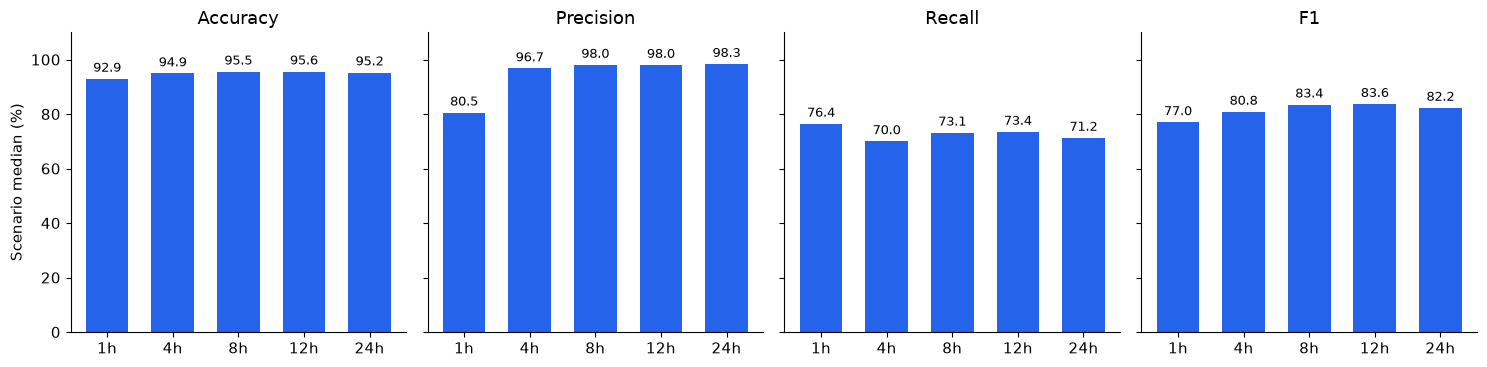

In [2]:
fig,axes=plt.subplots(1,4,figsize=(15,3.8),sharey=True)
for ax,k in zip(axes,metrics):
    bars=ax.bar([str(h)+'h' for h in hours],table[k]*100,color='#2563eb',width=.65)
    ax.bar_label(bars,fmt='%.1f',padding=3,fontsize=9)
    ax.set(title=k.capitalize(),ylim=(0,110),ylabel='Scenario median (%)' if ax is axes[0] else '')
fig.tight_layout(); display(fig); plt.close(fig)

## 2. 시나리오별 실제 수치

중앙값에 가려지는 약점을 확인한다. 점진적 악화 초기와 일주기 변화는 여전히 어려우며, 집계 해상도·정상 참고 품질에 영향을 받는다. 정답 구간 확장이나 point adjustment는 사용하지 않았다.

,hours,scenario,accuracy,precision,recall,f1,false_positive_rate
0,1,daily_pattern_change,85.142,81.127,52.872,64.021,4.100
1,1,gradual_degradation,89.271,79.821,61.635,69.559,3.868
2,1,long_latency_shift,91.752,76.312,69.375,72.678,4.045
3,1,sustained_input_drop,94.743,82.088,87.552,84.732,3.819
4,1,sustained_overload,94.053,79.166,83.414,81.235,4.005
5,1,volatility_growth,96.061,83.516,94.538,88.686,3.641
6,4,daily_pattern_change,85.785,95.810,45.117,61.346,0.658
7,4,gradual_degradation,90.775,96.976,55.343,70.470,0.428
8,4,long_latency_shift,93.483,96.476,61.014,74.752,0.419
9,4,sustained_input_drop,97.289,97.189,86.220,91.377,0.499


hours,1,4,8,12,24
scenario,,,,,
daily_pattern_change,64.02,61.35,63.30,64.71,51.82
gradual_degradation,69.56,70.47,73.36,73.63,73.18
long_latency_shift,72.68,74.75,78.36,79.02,78.23
sustained_input_drop,84.73,91.38,92.06,91.39,91.92
sustained_overload,81.23,86.81,88.50,88.25,86.24
volatility_growth,88.69,96.35,96.76,96.74,96.50


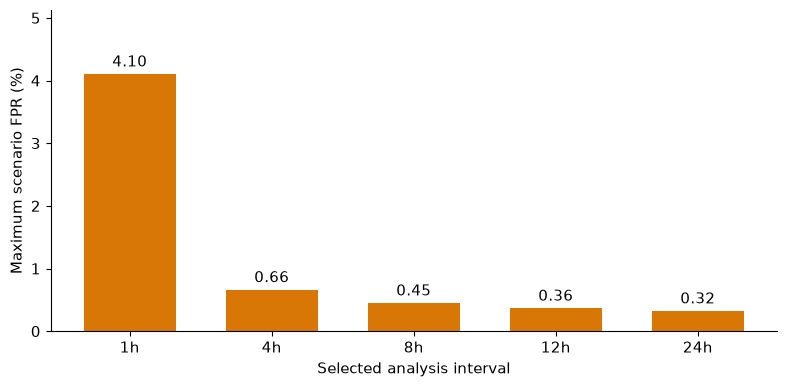

In [3]:
details=pd.DataFrame([{'hours':h,'scenario':name,**v} for h in hours for name,v in r[str(h)]['scenarios'].items()])
display(details[['hours','scenario',*metrics,'false_positive_rate']].assign(**{k:details[k]*100 for k in metrics+['false_positive_rate']}).round(3))
pivot=details.pivot(index='scenario',columns='hours',values='f1')*100
display(pivot.round(2))
fig,ax=plt.subplots(figsize=(8,4))
bars=ax.bar([str(h)+'h' for h in hours],table.max_scenario_fpr*100,color='#d97706',width=.65)
ax.bar_label(bars,fmt='%.2f',padding=3)
ax.set(ylabel='Maximum scenario FPR (%)',xlabel='Selected analysis interval',ylim=(0,max(table.max_scenario_fpr*100)*1.25))
fig.tight_layout(); display(fig); plt.close(fig)

## 적용 시 주의

- 선택 구간 밖 감시 로그·경보 상태는 사용하지 않지만 미리 고정한 정상 참고는 별도로 사용한다.
- 로그가 없다는 이유로 수집 상태를 정상으로 가정하지 않는다. 수집 불명은 판단 불가다.
- 같은 Adapter+Process의 정상 참고를 등록해야 하며, 미등록 집단을 임의의 정상 통계로 대체하지 않는다.
- 원본 데이터에는 실제 검토된 연속 28일 정상 참고가 확보되지 않았다. 이번 결과는 반합성 연구 검증이다.
- 원래 시간당 1점 평가와 다른 자료이므로 새 수치를 예전 평가 대비 향상 폭으로 주장하지 않는다.